In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import warnings
import re
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    fbeta_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import mannwhitneyu
from lightgbm import LGBMClassifier
from lightgbm.basic import LightGBMError
import shap

# 1 

## Loading Train Data Set

In [2]:
train = pd.read_excel(r"C:\Users\yashg\Downloads\May 12 Status Contracts.xlsx")
train_df = pd.DataFrame(train)


### Revove 2026 Data

In [3]:
train_df["Contract Start Date"] = pd.to_datetime(
    train_df["Contract Start Date"], dayfirst=True
)
train_df = train_df.loc[
    train_df["Contract Start Date"] < pd.Timestamp("2026-01-01")
].copy()
train_df["Contract Start Date"] = train_df["Contract Start Date"].dt.strftime("%d-%m-%Y")

## Load Test Data Set

In [4]:
test = pd.read_excel(r"C:\Users\yashg\Downloads\Raw Jan - Jun 2026.xlsx")
test_df = pd.DataFrame(test)

## Pre Processing

### Schema Harmonization & Separate Row-Wise Cleaning (Zero Leakage)

In [5]:
COLS_TO_DROP_RAW = [
    'Address', 'Claimed Employer', 'Claimed Employer Type', 'Claimed Position',
    'Credit Info ID', 'EV Employer', 'EV Employer Type', 'EV Position',
    'Gender', 'No of Dependents', 'Contract ID', 'Party No', 'Application No',
]


def harmonize_and_dedup(df_in: pd.DataFrame, name: str, reference_cols=None) -> pd.DataFrame:
    """Harmonize schema and deduplicate a single dataframe independently."""
    out = df_in.copy()
    if 'Unit Brand' in out.columns and 'Manufacturer' not in out.columns:
        out = out.rename(columns={'Unit Brand': 'Manufacturer'})
    out = out.drop(columns=['Product Type.1'], errors='ignore')
    if 'Borrower Type' not in out.columns:
        out['Borrower Type'] = 'Principal'

    out = out.drop(columns=COLS_TO_DROP_RAW, errors='ignore')
    if 'Current DPD' in out.columns and 'Longest_DPD' not in out.columns:
        out = out.rename(columns={'Current DPD': 'Longest_DPD'})

    n_before = len(out)
    n_dups = int(out.duplicated().sum())
    out = out.drop_duplicates().reset_index(drop=True)
    print(f"[{name}] Before dedup: {n_before} rows | Duplicates removed: {n_dups} | After dedup: {out.shape}")
    if out.empty:
        raise ValueError(
            f"[{name}] has 0 rows before preprocessing. "
            "Check the Excel input path and the Contract Start Date filter above."
        )

    if reference_cols is not None:
        ref_set = set(reference_cols)
        cur_set = set(out.columns)
        missing_cols = sorted(ref_set - cur_set)
        extra_cols = sorted(cur_set - ref_set)
        if missing_cols:
            print(f"[{name}] Adding missing columns from train schema as NaN: {missing_cols}")
            for col in missing_cols:
                out[col] = np.nan
        if extra_cols:
            print(f"[{name}] Dropping extra columns not in train schema: {extra_cols}")
        out = out[list(reference_cols)].copy()

    return out


def clean_income(x):
    if pd.isna(x):
        return np.nan
    x = str(x).lower().strip()
    if any(w in x for w in ['confidential', 'not disclosed', 'not provided', 'proof', 'coec', 'pls refer', 'cannot disclose']):
        return np.nan
    x = x.replace(',', '')
    x = re.sub(r'(\d+)k', r'\1000', x)
    nums = re.findall(r'\d+', x)
    if len(nums) == 1:
        value = float(nums[0])
        if 'annual' in x:
            value /= 12
        return value
    elif len(nums) >= 2:
        return float(np.mean([float(nums[0]), float(nums[1])]))
    return np.nan


def clean_tenure(x):
    if pd.isna(x):
        return np.nan
    x = str(x).lower().strip().replace('?', '')
    if re.match(r'^\d+$', x):
        return float(x)
    years = re.search(r'(\d+)\s*(year|years|yr|yrs)', x)
    months = re.search(r'(\d+)\s*(month|months|mos)', x)
    y = int(years.group(1)) if years else 0
    m = int(months.group(1)) if months else 0
    if y > 0 or m > 0:
        return float(y * 12 + m)
    nums = re.findall(r'\d+', x)
    return float(nums[0]) if nums else np.nan


def preprocess_individual_df(df_in: pd.DataFrame, name: str) -> pd.DataFrame:
    """Apply deterministic row-wise cleaning independently (no dataset statistics used)."""
    out = df_in.copy()

    income_cols = [c for c in ['Claimed Income', 'EV Income', 'BV Income'] if c in out.columns]
    tenure_cols = [c for c in ['Claimed Tenure', 'EV Tenure', 'BV Tenure', 'Residence Tenure'] if c in out.columns]

    for col in income_cols:
        num_s = pd.to_numeric(out[col], errors='coerce')
        mask = num_s.isnull()
        parsed = pd.to_numeric(out.loc[mask, col].apply(clean_income), errors='coerce')
        out[col] = num_s.where(~mask, parsed)

    for col in tenure_cols:
        num_s = pd.to_numeric(out[col], errors='coerce')
        mask = num_s.isnull()
        parsed = pd.to_numeric(out.loc[mask, col].apply(clean_tenure), errors='coerce')
        out[col] = num_s.where(~mask, parsed)

    if income_cols or tenure_cols:
        out[income_cols + tenure_cols] = out[income_cols + tenure_cols].apply(pd.to_numeric, errors='coerce')

    out['Longest_DPD'] = pd.to_numeric(out['Longest_DPD'], errors='coerce').fillna(0)

    # Flag missingness BEFORE any imputation; normalize sentinel -999 to NaN
    flag_cols = [
        'BAP Amount', 'EV Income', 'EV Tenure',
        'BV Income', 'Price Gap', 'BV Tenure', 'DSCR',
        'Claimed Tenure', 'Claimed Income', 'Residence Tenure',
    ]
    for col in flag_cols:
        if col in out.columns:
            val_num = pd.to_numeric(out[col], errors='coerce')
            out[f'{col}_missing'] = (val_num.isnull() | (val_num == -999)).astype(int)
            out[col] = val_num.replace(-999, np.nan)

    num_cols = out.select_dtypes(include=[np.number]).columns
    out[num_cols] = out[num_cols].replace(-999, np.nan)

    cat_fill_cols = [
        'Loan History', 'BAP Type', 'Citizenship',
        'Type of Unit', 'Dealer Name', 'Borrower Type', 'Employment Type',
        'Home Ownership', 'Manufacturer', 'Submitted ID', 'Mode of Payment',
    ]
    for col in cat_fill_cols:
        if col in out.columns:
            out[col] = out[col].fillna('Unknown')

    # Parse Contract Start Date as datetime here; impute missing mode ONLY from train_part after splitting
    if 'Contract Start Date' in out.columns:
        out['Contract Start Date'] = pd.to_datetime(
            out['Contract Start Date'], dayfirst=True, errors='coerce'
        )

    out = out.drop(columns=['Birthday', 'BAP Date'], errors='ignore')

    if 'Marital Status' in out.columns:
        out['Marital Status'] = out['Marital Status'].replace({
            'Separated': 'Without Partner',
            'Divorced': 'Without Partner',
            'Single': 'Single/Not Married',
            'Not Married': 'Single/Not Married',
        })
        out = out[~out['Marital Status'].isin(['Partner', 'Unspecified'])].copy()

    if out.empty:
        raise ValueError(
            f"[{name}] has 0 rows remaining after Marital Status filtering."
        )

    out['Target'] = out['Longest_DPD'].apply(lambda x: 0 if pd.isna(x) or x <= 0 else 1)
    out = out.reset_index(drop=True)
    print(f"[{name}] Cleaned shape: {out.shape} | Default rate: {out['Target'].mean():.3f}")
    return out


# Step 1: Preprocess train_df and test_df completely separately
train_df = harmonize_and_dedup(train_df, name='train_df')
test_df = harmonize_and_dedup(test_df, name='test_df', reference_cols=train_df.columns)

train_df = preprocess_individual_df(train_df, name='train_df')
test_df = preprocess_individual_df(test_df, name='test_df')

[train_df] Before dedup: 20140 rows | Duplicates removed: 0 | After dedup: (20140, 35)
[test_df] Before dedup: 2845 rows | Duplicates removed: 0 | After dedup: (2845, 35)
[train_df] Cleaned shape: (20119, 44) | Default rate: 0.207
[test_df] Cleaned shape: (2845, 44) | Default rate: 0.249


### Train / Validation Split + Train-Only Date Imputation & Winsorization

In [6]:
# Split ONLY train_df into train and validation BEFORE fitting any dataset statistics.
# test_df stays completely separate throughout.
train_part, val_part = train_test_split(
    train_df, test_size=0.111, random_state=42, stratify=train_df['Target']
)
train_part = train_part.reset_index(drop=True)
val_part = val_part.reset_index(drop=True)
test_part = test_df.reset_index(drop=True)

print(f"Split sizes -> Train: {len(train_part)} | Val: {len(val_part)} | Separate Test: {len(test_part)}")
print(
    f"Default rates -> Train: {train_part['Target'].mean():.3f} | "
    f"Val: {val_part['Target'].mean():.3f} | Test: {test_part['Target'].mean():.3f}"
)

# 1) Contract Start Date mode fitted ONLY on train_part
if 'Contract Start Date' in train_part.columns:
    valid_dates = train_part['Contract Start Date'].dropna()
    contract_date_mode = valid_dates.mode().iloc[0] if not valid_dates.empty else pd.Timestamp('2024-01-01')
    for part in (train_part, val_part, test_part):
        part['Contract Start Date'] = part['Contract Start Date'].fillna(contract_date_mode)
        part['Contract_Year'] = part['Contract Start Date'].dt.year
        part['Contract_Month'] = part['Contract Start Date'].dt.month
        part.drop(columns=['Contract Start Date'], inplace=True)

# 2) Winsorization quantiles (1% / 99%) fitted ONLY on train_part
winsor_cols = [
    'Loan Amort', 'Claimed Income', 'Downpayment', 'Amount Finance',
    'Residence Tenure', 'BV Income', 'EV Income', 'BAP Amount',
    'Claimed Tenure', 'Interest Rate', 'Price Gap', 'DSCR',
]
winsor_bounds = {}
for col in winsor_cols:
    if col in train_part.columns:
        winsor_bounds[col] = (
            train_part[col].quantile(0.01),
            train_part[col].quantile(0.99),
        )

for part in (train_part, val_part, test_part):
    for col, (lo, hi) in winsor_bounds.items():
        if col in part.columns and pd.notna(lo) and pd.notna(hi):
            part[col] = part[col].clip(lower=lo, upper=hi)

Split sizes -> Train: 17885 | Val: 2234 | Separate Test: 2845
Default rates -> Train: 0.207 | Val: 0.207 | Test: 0.249


### Feature Engineering (Row-Wise per Split + Train-Fitted Quantiles & Categories)

In [7]:
EPS = 1e-9

_LOAN_HISTORY_RISK = {
    'With history of Pastdue': 3,
    'Poor Handling': 3,
    'Loans and other credit dealings seen on CIC': 2,
    'Existing client of JFP less than 25% Paid': 2,
    'Repeat clients of other Banks and Finances': 1,
    'Existing client of JFP 25% and above Paid': 1,
    'Existing client of JFP 50% and above Paid': 0,
    'Fully paid Good Repeat Client': 0,
}

_MOP_RISK = {
    'OTC - Bank': 4,
    'OTC - Gcash (Merchant)': 3,
    'ADA - Security': 3,
    'OTC': 3,
    'ADA - BPI': 2,
    'ADA - RCBC': 2,
    'ADA - BDO': 2,
    'ADA - Metrobank': 1,
    'PDC': 1,
    'ADA - Eastwest': 0,
    'Salary Deduction': 0,
    'OTC - Gcash (Bank Transfer)': 0,
}


def engineer_row_features(df_in: pd.DataFrame) -> pd.DataFrame:
    """Compute deterministic row-wise domain features on an individual dataframe."""
    out = df_in.copy()

    out['DTI'] = out['Loan Amort'] / out['Claimed Income'].replace(0, np.nan)
    out['Income_Gap'] = out['Claimed Income'] - out['BV Income']
    out['LTV'] = out['Amount Finance'] / (out['Amount Finance'] + out['Downpayment']).replace(0, np.nan)
    out['Repayment_Stress'] = out['Loan Amort'] / out['Amount Finance'].replace(0, np.nan)

    out['BAP_to_Finance'] = out['BAP Amount'] / out['Amount Finance'].replace(0, np.nan)
    out['BAP_Income_Risk'] = ((out['BAP Amount'] > 200000) & (out['Income_Gap'] < 0)).astype(int)
    out['BAP_Asset_Risk'] = ((out['BAP Amount'] > 200000) & (out['Price Gap'] < -50000)).astype(int)
    out['Collateral_Shortfall'] = (-out['Price Gap']).clip(lower=0) / (out['Amount Finance'] + EPS)
    out['Rate_x_Term'] = out['Interest Rate'] * out['Payment Terms']
    out['Equity_Cushion'] = out['Downpayment'] / (out['Downpayment'] + out['Amount Finance'] + EPS)

    out['Shortfall_x_Term'] = out['Collateral_Shortfall'] * out['Payment Terms']
    out['Income_Gap_x_LTV'] = out['Income_Gap'] * out['LTV']
    out['DTI_x_LTV'] = out['DTI'] * out['LTV']
    out['DP_to_Income'] = out['Downpayment'] / out['Claimed Income'].replace(0, np.nan)
    out['Age_at_Maturity'] = out['Age as of Contract'] + out['Payment Terms'] / 12

    if 'BV Tenure' in out.columns:
        out['Tenure_Mismatch'] = (out['Claimed Tenure'] - out['BV Tenure']).abs()

    if {'BV Income', 'Claimed Income'}.issubset(out.columns):
        out['Income_Inconsistency'] = (out['BV Income'] / (out['Claimed Income'] + EPS)).clip(upper=5)

    _verif_cols = [
        'EV Income', 'BV Income', 'EV Tenure', 'BV Tenure',
        'Price Gap', 'DSCR', 'Claimed Income', 'Claimed Tenure',
    ]
    out['Verification_Gaps'] = sum(out[c].isna().astype(int) for c in _verif_cols if c in out.columns)
    out['High_Risk_Missing'] = (
        (out['BV Tenure_missing'] == 1) & (out['Claimed Tenure_missing'] == 1)
    ).astype(int)
    out['Unverified_Income_AND_Tenure'] = (
        (out['BV Income_missing'] == 1) & (out['Claimed Tenure_missing'] == 1)
    ).astype(int)

    out['Loan_History_Risk'] = out['Loan History'].map(_LOAN_HISTORY_RISK).fillna(1)

    _pt = pd.to_numeric(out['Payment Terms'], errors='coerce')
    _dp = pd.to_numeric(out['Downpayment %'], errors='coerce')
    out['Long_Term_Loan'] = (_pt >= 37).astype(int)
    out['Danger_DP_Band'] = ((_dp >= 15) & (_dp < 20)).astype(int)
    out['Safe_DP'] = (_dp >= 30).astype(int)
    out['LongTerm_x_DangerDP'] = ((_pt.fillna(0) >= 37) & (_dp >= 15) & (_dp < 20)).astype(int)

    if 'BAP Type' in out.columns:
        out['BAP_Adverse_Loans_Only'] = (out['BAP Type'] == 'Adverse Loans').astype(int)

    out['MOP_Risk_Score'] = out['Mode of Payment'].map(_MOP_RISK).fillna(1)
    out['High_Risk_MOP'] = out['Mode of Payment'].isin(
        ['OTC', 'ADA - Security', 'OTC - Gcash (Merchant)']
    ).astype(int)
    return out


train_part = engineer_row_features(train_part)
val_part = engineer_row_features(val_part)
test_part = engineer_row_features(test_part)

# High_DTI threshold fitted ONLY on train_part
dti_q75_train = train_part['DTI'].quantile(0.75)
for part in (train_part, val_part, test_part):
    part['High_DTI'] = (part['DTI'] > dti_q75_train).astype(int)

print(
    f"Train High_Risk_Missing: {train_part['High_Risk_Missing'].sum()} | "
    f"Test High_Risk_Missing: {test_part['High_Risk_Missing'].sum()}"
)


def split_xy_and_sanitize(part: pd.DataFrame):
    X_p = part.drop(columns=['Longest_DPD', 'Target'])
    y_p = part['Target'].copy()
    X_p.columns = ["".join(c if c.isalnum() else "_" for c in str(c)) for c in X_p.columns]
    return X_p, y_p


X_train, y_train = split_xy_and_sanitize(train_part)
X_val, y_val = split_xy_and_sanitize(val_part)
X_test, y_test = split_xy_and_sanitize(test_part)

drop_cols = [
    'Citizenship', 'Is_Recent_Contract', 'Income_Ratio',
    'Loan_History', 'Contract_Year', 'Type_of_Unit', 'Borrower_Type',
    'Dealer_Default_Rate', 'LoanHistory_x_DealerRisk', 'Dealer_x_LowDP', 'Dealer_x_Term',
    'High_Risk_Dealer', 'Mid_Risk_Dealer', 'Dealer_Risk_Tier', 'GoodBorrower_RiskyDealer',
] + [c for c in X_train.columns if 'submit' in c.lower()]

for part_X in (X_train, X_val, X_test):
    part_X.drop(columns=[c for c in drop_cols if c in part_X.columns], inplace=True)

# Ensure exact identical feature set/order
X_val = X_val[X_train.columns].copy()
X_test = X_test[X_train.columns].copy()

# Fit CategoricalDtype ONLY on X_train so .cat.codes match across train, val, and test
cat_cols = X_train.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
train_cat_dtypes = {}
for col in cat_cols:
    X_train[col] = X_train[col].fillna('Unknown').astype(str).astype('category')
    train_cat_dtypes[col] = X_train[col].dtype
    X_val[col] = X_val[col].fillna('Unknown').astype(str).astype(train_cat_dtypes[col])
    X_test[col] = X_test[col].fillna('Unknown').astype(str).astype(train_cat_dtypes[col])

print(f"Prepared feature matrices -> X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")

Train High_Risk_Missing: 1881 | Test High_Risk_Missing: 130
Prepared feature matrices -> X_train: (17885, 66) | X_val: (2234, 66) | X_test: (2845, 66)


## Model

### OOF Dealer Risk Features & OOF Target Encoding (Train-Only Fitting)

In [8]:
# 1) Dealer Default Rate & Risk Tiers — 5-fold OOF on X_train; full train mapping on X_val and X_test
DEALER_SMOOTH = 10
DEALER_SPLITS = 5
global_rate = float(y_train.mean())
dealer_col_name = 'Dealer_Name'

if dealer_col_name in X_train.columns:
    s_dealer_tr = X_train[dealer_col_name].astype(str)
    dealer_stats = y_train.groupby(s_dealer_tr).agg(['mean', 'count'])
    dealer_smooth = (
        dealer_stats['mean'] * dealer_stats['count'] + global_rate * DEALER_SMOOTH
    ) / (dealer_stats['count'] + DEALER_SMOOTH)

    # Build every training rate and tier without using that row's target.
    kf_dealer = KFold(n_splits=DEALER_SPLITS, shuffle=True, random_state=42)
    oof_dealer_rate = pd.Series(np.nan, index=X_train.index, dtype=float)
    oof_dealer_tier = pd.Series(np.nan, index=X_train.index, dtype=float)
    for tr_idx, oof_idx in kf_dealer.split(X_train):
        s_f = s_dealer_tr.iloc[tr_idx]
        y_f = y_train.iloc[tr_idx]
        fold_rate = float(y_f.mean())
        g_f = y_f.groupby(s_f).agg(['mean', 'count'])
        rate_f = (g_f['mean'] * g_f['count'] + fold_rate * DEALER_SMOOTH) / (g_f['count'] + DEALER_SMOOTH)
        oof_rates_f = s_dealer_tr.iloc[oof_idx].map(rate_f).fillna(fold_rate)
        oof_dealer_rate.iloc[oof_idx] = oof_rates_f.values
        mid_f = float(rate_f.quantile(0.70))
        high_f = float(rate_f.quantile(0.90))
        oof_dealer_tier.iloc[oof_idx] = np.where(
            oof_rates_f <= mid_f, 0, np.where(oof_rates_f <= high_f, 1, 2)
        )

    oof_dealer_rate = oof_dealer_rate.fillna(global_rate)

    tier_high_cutoff = float(dealer_smooth.quantile(0.90))
    tier_mid_cutoff = float(dealer_smooth.quantile(0.70))
    dti_30_train = float(X_train['DTI'].quantile(0.30))

    def _assign_dealer_features(df_part: pd.DataFrame, dr_series: pd.Series, tier_values):
        dr_vals = dr_series.to_numpy(dtype=float)
        df_part['Dealer_Default_Rate'] = dr_vals
        df_part['LoanHistory_x_DealerRisk'] = df_part['Loan_History_Risk'].to_numpy(dtype=float) * dr_vals
        df_part['Dealer_x_LowDP'] = dr_vals * (1.0 - df_part['Downpayment__'].to_numpy(dtype=float) / 100.0)
        df_part['Dealer_x_Term'] = dr_vals * df_part['Payment_Terms'].to_numpy(dtype=float)

        tier = np.asarray(tier_values, dtype=int)
        df_part['Dealer_Risk_Tier'] = tier
        df_part['High_Risk_Dealer'] = (tier == 2).astype(int)
        df_part['Mid_Risk_Dealer'] = (tier == 1).astype(int)
        df_part['GoodBorrower_RiskyDealer'] = (
            (tier >= 1) & (df_part['DTI'].to_numpy(dtype=float) < dti_30_train)
        ).astype(int)
        df_part['HighRiskMOP_x_DealerTier'] = (
            df_part['High_Risk_MOP'].to_numpy() * tier
        )
        df_part['Verification_Gaps_x_DealerRate'] = (
            df_part['Verification_Gaps'].to_numpy(dtype=float) * dr_vals
        )
        if 'BV_Tenure_missing' in df_part.columns:
            df_part['BV_Missing_x_DealerRate'] = (
                df_part['BV_Tenure_missing'].to_numpy(dtype=float) * dr_vals
            )

    val_test_rates = [
        frame[dealer_col_name].astype(str).map(dealer_smooth).fillna(global_rate)
        for frame in (X_val, X_test)
    ]
    def _full_train_tier(rates):
        return np.where(
            rates <= tier_mid_cutoff, 0,
            np.where(rates <= tier_high_cutoff, 1, 2),
        )

    _assign_dealer_features(X_train, oof_dealer_rate, oof_dealer_tier)
    _assign_dealer_features(X_val, val_test_rates[0], _full_train_tier(val_test_rates[0]))
    _assign_dealer_features(X_test, val_test_rates[1], _full_train_tier(val_test_rates[1]))

    print(f"Dealer default rate features added (OOF train). Train mean: {X_train['Dealer_Default_Rate'].mean():.4f} | Test mean: {X_test['Dealer_Default_Rate'].mean():.4f}")
    print(f"Train tier counts: {X_train['Dealer_Risk_Tier'].value_counts().sort_index().to_dict()}")
else:
    print(f"WARNING: '{dealer_col_name}' column not found — skipping dealer features")

# 2) OOF Target Encoding on high-cardinality categorical columns
TE_SMOOTH = 20
TE_SPLITS = 5
TE_SEED = 42
te_cols_raw = [
    'Dealer_Name', 'Manufacturer', 'Asset', 'Employment_Type',
    'Product_Type', 'Home_Ownership', 'Loan_History', 'BAP_Type', 'Mode_of_Payment',
]
te_cols = [c for c in te_cols_raw if c in X_train.columns]
print(f"Target-encoding: {te_cols}")

global_mean = float(y_train.mean())
kf = KFold(n_splits=TE_SPLITS, shuffle=True, random_state=TE_SEED)
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

for col in te_cols:
    s_tr = X_train[col].astype(str)
    grp = y_train.groupby(s_tr).agg(['mean', 'count'])
    enc_full = (grp['mean'] * grp['count'] + global_mean * TE_SMOOTH) / (grp['count'] + TE_SMOOTH)

    oof = pd.Series(np.nan, index=X_train.index, dtype=float)
    for tr_idx, oof_idx in kf.split(X_train):
        s_fold = s_tr.iloc[tr_idx]
        y_fold = y_train.iloc[tr_idx]
        grp_f = y_fold.groupby(s_fold).agg(['mean', 'count'])
        fold_mean = float(y_fold.mean())
        enc_f = (grp_f['mean'] * grp_f['count'] + fold_mean * TE_SMOOTH) / (grp_f['count'] + TE_SMOOTH)
        oof.iloc[oof_idx] = s_tr.iloc[oof_idx].map(enc_f).fillna(fold_mean).values

    X_train[f'{col}_TE'] = oof.fillna(global_mean).values
    X_val[f'{col}_TE'] = X_val[col].astype(str).map(enc_full).fillna(global_mean).values
    X_test[f'{col}_TE'] = X_test[col].astype(str).map(enc_full).fillna(global_mean).values
    print(f"  {col}_TE  train={X_train[col + '_TE'].mean():.4f}  test={X_test[col + '_TE'].mean():.4f}")

drop_high_card = ['Dealer_Name', 'Asset', 'Manufacturer', 'Loan_History', 'BAP_Type']
for f in (X_train, X_val, X_test):
    f.drop(columns=[c for c in drop_high_card if c in f.columns], inplace=True)

cat_cols = [c for c in cat_cols if c not in drop_high_card]
active_cats = [c for c in cat_cols if c in X_train.columns]

X_train_enc = X_train.copy()
X_val_enc = X_val.copy()
X_test_enc = X_test.copy()
for col in active_cats:
    # Unseen val/test categories map to -1, which LightGBM treats as missing category cleanly
    X_train_enc[col] = X_train_enc[col].cat.codes
    X_val_enc[col] = X_val_enc[col].cat.codes
    X_test_enc[col] = X_test_enc[col].cat.codes

Dealer default rate features added (OOF train). Train mean: 0.2056 | Test mean: 0.2095
Train tier counts: {0: 14862, 1: 1095, 2: 1928}
Target-encoding: ['Dealer_Name', 'Manufacturer', 'Asset', 'Employment_Type', 'Product_Type', 'Home_Ownership', 'BAP_Type', 'Mode_of_Payment']
  Dealer_Name_TE  train=0.2045  test=0.2087
  Manufacturer_TE  train=0.2078  test=0.2115
  Asset_TE  train=0.2116  test=0.2296
  Employment_Type_TE  train=0.2077  test=0.2062
  Product_Type_TE  train=0.2059  test=0.2115
  Home_Ownership_TE  train=0.2074  test=0.2071
  BAP_Type_TE  train=0.2070  test=0.2270
  Mode_of_Payment_TE  train=0.2068  test=0.2141


### MissForest Iterative Imputation & Median Fallback (Train-Only Fitting)

In [9]:
IMPUTE_COLS = ['Claimed_Income', 'Claimed_Tenure', 'DSCR', 'Residence_Tenure']
impute_cols_present = [
    c for c in IMPUTE_COLS
    if c in X_train_enc.columns and X_train_enc[c].notna().any()
]

for split_name, split_df in (('X_train_enc', X_train_enc), ('X_val_enc', X_val_enc), ('X_test_enc', X_test_enc)):
    if len(split_df) == 0:
        raise ValueError(
            f"{split_name} has 0 rows; cannot run IterativeImputer. "
            "Verify that train_df and test_df both contain rows after date and Marital Status filtering."
        )

if impute_cols_present:
    imputer = IterativeImputer(
        estimator=RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1),
        max_iter=5,
        random_state=42,
    )
    X_train_enc[impute_cols_present] = imputer.fit_transform(X_train_enc[impute_cols_present])
    X_val_enc[impute_cols_present] = imputer.transform(X_val_enc[impute_cols_present])
    X_test_enc[impute_cols_present] = imputer.transform(X_test_enc[impute_cols_present])
    print(f"MissForest imputation done on: {impute_cols_present}")

train_medians = X_train_enc.median(numeric_only=True).fillna(0.0)
for df_part in (X_train_enc, X_val_enc, X_test_enc):
    for col in df_part.select_dtypes(include=[np.number]).columns:
        if df_part[col].isnull().any():
            df_part[col] = df_part[col].fillna(train_medians.get(col, 0.0))
    for col in df_part.select_dtypes(include=['object', 'string']).columns:
        if df_part[col].isnull().any():
            df_part[col] = df_part[col].fillna('Unknown')

print(
    f"Missing after imputation -> train: {X_train_enc.isnull().sum().sum()}, "
    f"val: {X_val_enc.isnull().sum().sum()}, test: {X_test_enc.isnull().sum().sum()}"
)

MissForest imputation done on: ['Claimed_Income', 'Claimed_Tenure', 'DSCR', 'Residence_Tenure']
Missing after imputation -> train: 0, val: 0, test: 0


### Cohen's d Feature Scoring & Binary Splits (Train-Only Fitting)

In [10]:
def rank_features_by_split_cohens_d(X_enc: pd.DataFrame, y: pd.Series, n_thresholds: int = 50) -> pd.DataFrame:
    y_arr = y.values.astype(float)
    results = []
    numeric_cols = [c for c in X_enc.columns if pd.api.types.is_numeric_dtype(X_enc[c])]

    for col in numeric_cols:
        x = X_enc[col].values.astype(float)
        valid = ~np.isnan(x)
        xv, yv = x[valid], y_arr[valid]
        if len(xv) < 10:
            results.append({'Feature': col, 'Best_Threshold': None, 'Split_Cohens_d': 0.0})
            continue

        thresholds = np.percentile(xv, np.linspace(5, 95, n_thresholds))
        left = xv[None, :] <= thresholds[:, None]
        n_left = left.sum(axis=1)
        n_right = len(xv) - n_left
        valid_t = (n_left >= 5) & (n_right >= 5)

        if not valid_t.any():
            results.append({'Feature': col, 'Best_Threshold': None, 'Split_Cohens_d': 0.0})
            continue

        sum_left = left.dot(yv)
        mean_left = np.where(n_left > 0, sum_left / n_left, 0.0)
        mean_right = np.where(n_right > 0, (yv.sum() - sum_left) / n_right, 0.0)

        y2 = yv ** 2
        sum2_left = left.dot(y2)
        var_left = np.where(n_left > 1, sum2_left / n_left - mean_left ** 2, 0.0)
        var_right = np.where(n_right > 1, (y2.sum() - sum2_left) / n_right - mean_right ** 2, 0.0)
        pooled_std = np.sqrt((np.maximum(var_left, 0) + np.maximum(var_right, 0)) / 2)

        with np.errstate(divide='ignore', invalid='ignore'):
            d = np.where(pooled_std > 0, np.abs(mean_left - mean_right) / pooled_std, 0.0)
        d[~valid_t] = 0.0

        best_idx = int(np.argmax(d))
        best_score = float(d[best_idx])
        results.append({
            'Feature': col,
            'Best_Threshold': round(float(thresholds[best_idx]), 4) if best_score > 0 else None,
            'Split_Cohens_d': round(best_score, 4),
        })

    return pd.DataFrame(results).sort_values('Split_Cohens_d', ascending=False).reset_index(drop=True)


print("Running Cohen's d scoring (train-only, vectorized)...")
split_df = rank_features_by_split_cohens_d(X_train_enc, y_train)

strong_split = split_df[split_df['Split_Cohens_d'] > 0.5]['Feature'].tolist()
moderate_split = split_df[(split_df['Split_Cohens_d'] > 0.2) & (split_df['Split_Cohens_d'] <= 0.5)]['Feature'].tolist()
print(f"Strong (d>0.5)  : {strong_split}")
print(f"Moderate (d>0.2): {moderate_split}")

cohens_d_order = split_df['Feature'].tolist()
remaining = [c for c in X_train_enc.columns if c not in cohens_d_order]
final_col_order = [c for c in cohens_d_order if c in X_train_enc.columns] + remaining

X_train_cd = X_train_enc[final_col_order].copy()
X_val_cd = X_val_enc[final_col_order].copy()
X_test_cd = X_test_enc[final_col_order].copy()

cohens_d_best = split_df.set_index('Feature')['Best_Threshold'].to_dict()
for feat in strong_split:
    if feat not in X_train_cd.columns or cohens_d_best.get(feat) is None:
        continue
    thresh = cohens_d_best[feat]
    col_name = f'{feat}_cd_split'
    X_train_cd[col_name] = (X_train_cd[feat] <= thresh).astype(int)
    X_val_cd[col_name] = (X_val_cd[feat] <= thresh).astype(int)
    X_test_cd[col_name] = (X_test_cd[feat] <= thresh).astype(int)
    print(f"Binary split: {col_name} (t={thresh:.4f})")

X_train_cd = X_train_cd.loc[:, ~X_train_cd.columns.duplicated()]
X_val_cd = X_val_cd.loc[:, ~X_val_cd.columns.duplicated()]
X_test_cd = X_test_cd.loc[:, ~X_test_cd.columns.duplicated()]

X_train_val_cd = pd.concat([X_train_cd, X_val_cd]).reset_index(drop=True)
y_train_val_cd = pd.concat([y_train, y_val]).reset_index(drop=True)

redundant_cols = [
    'LoanHistory_x_DealerRisk_cd_split',
    'Dealer_x_LowDP_cd_split',
    'Dealer_Default_Rate_cd_split',
    'Dealer_x_Term_cd_split',
    'GoodBorrower_RiskyDealer_cd_split',
    'High_Risk_Dealer_cd_split',
    'HighRiskMOP_x_DealerTier_cd_split',
    'High_DTI',
    'GoodBorrower_RiskyDealer',
]

for _df in (X_train_cd, X_val_cd, X_test_cd, X_train_val_cd):
    _df.drop(columns=[c for c in redundant_cols if c in _df.columns], inplace=True)

print(f"Features remaining after dropping redundant columns: {X_train_cd.shape[1]}")

Running Cohen's d scoring (train-only, vectorized)...
Strong (d>0.5)  : ['MOP_Risk_Score']
Moderate (d>0.2): ['Downpayment__', 'BAP_Adverse_Loans_Only', 'Equity_Cushion', 'Dealer_x_Term', 'LTV', 'Payment_Terms', 'Repayment_Stress', 'Dealer_x_LowDP', 'Rate_x_Term', 'Dealer_Name_TE', 'Product_Type_TE', 'Dealer_Default_Rate', 'Dealer_Risk_Tier', 'High_Risk_Dealer', 'Verification_Gaps_x_DealerRate', 'BAP_Type_TE', 'LoanHistory_x_DealerRisk', 'DTI_x_LTV', 'Interest_Rate', 'DTI', 'Long_Term_Loan', 'BAP_Amount', 'HighRiskMOP_x_DealerTier', 'Employment_Type_TE', 'Asset_TE', 'Manufacturer_TE', 'BV_Missing_x_DealerRate', 'BAP_to_Finance', 'EV_Tenure']
Binary split: MOP_Risk_Score_cd_split (t=3.0000)
Features remaining after dropping redundant columns: 80


### Neyman-Pearson Optuna (300 trials)

In [11]:
MAX_NP_FPR = 0.035


def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 200, 1500),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'num_leaves': trial.suggest_int('num_leaves', 20, 200),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 60),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 1.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 1.0, log=True),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 3.0, 20.0),
    }
    model = LGBMClassifier(**params, random_state=42, verbose=-1)
    model.fit(X_train_cd, y_train, categorical_feature=active_cats)
    proba = model.predict_proba(X_val_cd)[:, 1]
    fpr_v, tpr_v, _ = roc_curve(y_val, proba)
    valid = np.where(fpr_v <= MAX_NP_FPR)[0]
    return float(tpr_v[valid[-1]]) if len(valid) > 0 else 0.0


print(f"Neyman-Pearson Optuna (300 trials, FPR<={MAX_NP_FPR})...")
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=300, show_progress_bar=True)

best_params = study.best_params
print(f"Best params : {best_params}")
print(f"Best val recall at FPR<={MAX_NP_FPR}: {study.best_value:.4f}")

Neyman-Pearson Optuna (300 trials, FPR<=0.035)...
Best params : {'n_estimators': 1289, 'max_depth': 3, 'num_leaves': 65, 'min_child_samples': 6, 'learning_rate': 0.015780334198593607, 'subsample': 0.7319657150191409, 'colsample_bytree': 0.6717048101013421, 'reg_alpha': 0.001581762761360965, 'reg_lambda': 0.0006876413099244383, 'scale_pos_weight': 18.465037281616286}
Best val recall at FPR<=0.035: 0.1361


Best trial: 231. Best value: 0.136069: 100%|##########| 300/300 [10:56<00:00,  2.19s/it]


### Final Model + Separate Test Set Evaluation

Threshold selected on validation set (FPR<=0.035): 0.9092

              precision    recall  f1-score   support

  No Default       0.76      0.94      0.84      2137
     Default       0.39      0.12      0.19       708

    accuracy                           0.73      2845
   macro avg       0.58      0.53      0.51      2845
weighted avg       0.67      0.73      0.68      2845

Test  ->  TN: 1999  FP: 138  FN: 620  TP: 88
FN Rate: 0.876  |  FP Rate: 0.065  |  AUC: 0.6351


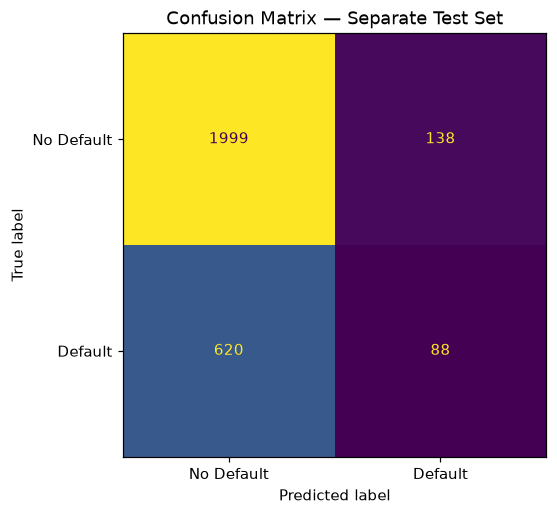

In [12]:
# Select operating threshold strictly on validation set using best_params from Optuna
threshold_model = LGBMClassifier(
    **best_params,
    random_state=42,
    verbose=-1,
    deterministic=True,
    force_row_wise=True,
)
threshold_model.fit(X_train_cd, y_train, categorical_feature=active_cats)

val_proba = threshold_model.predict_proba(X_val_cd)[:, 1]
fpr_v, tpr_v, thresholds_v = roc_curve(y_val, val_proba)
valid_idx_v = np.where(fpr_v <= MAX_NP_FPR)[0]
best_thresh = float(thresholds_v[valid_idx_v[-1]]) if len(valid_idx_v) > 0 else 0.5
print(f"Threshold selected on validation set (FPR<={MAX_NP_FPR}): {best_thresh:.4f}")

# Fit the final model on train+validation and evaluate once on the separate test set
final_model = LGBMClassifier(
    **best_params,
    random_state=42,
    verbose=-1,
    deterministic=True,
    force_row_wise=True,
)
final_model.fit(X_train_val_cd, y_train_val_cd, categorical_feature=active_cats)

test_proba = final_model.predict_proba(X_test_cd)[:, 1]
test_auc = roc_auc_score(y_test, test_proba)
y_pred = (test_proba >= best_thresh).astype(int)

print("\n" + classification_report(y_test, y_pred, target_names=['No Default', 'Default']))

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
fn_rate = fn / (fn + tp) if (fn + tp) else 0.0
fp_rate = fp / (fp + tn) if (fp + tn) else 0.0

print(f"Test  ->  TN: {tn}  FP: {fp}  FN: {fn}  TP: {tp}")
print(f"FN Rate: {fn_rate:.3f}  |  FP Rate: {fp_rate:.3f}  |  AUC: {test_auc:.4f}")

disp = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['No Default', 'Default'])
disp.plot(colorbar=False)
plt.title("Confusion Matrix — Separate Test Set")
plt.tight_layout()
plt.show()

### Feature Importances

Top 20 feature importances:
                 Feature  Importance
            Product_Type         513
          Dealer_x_LowDP         387
           Interest_Rate         351
             Rate_x_Term         348
           Dealer_x_Term         347
                Asset_TE         337
      Employment_Type_TE         285
         Age_at_Maturity         278
              Loan_Amort         254
         Manufacturer_TE         252
                    DSCR         237
          Claimed_Tenure         225
        Residence_Tenure         216
         Product_Type_TE         213
 BV_Missing_x_DealerRate         203
               EV_Tenure         201
      Mode_of_Payment_TE         191
           Downpayment__         184
          Marital_Status         177
LoanHistory_x_DealerRisk         167


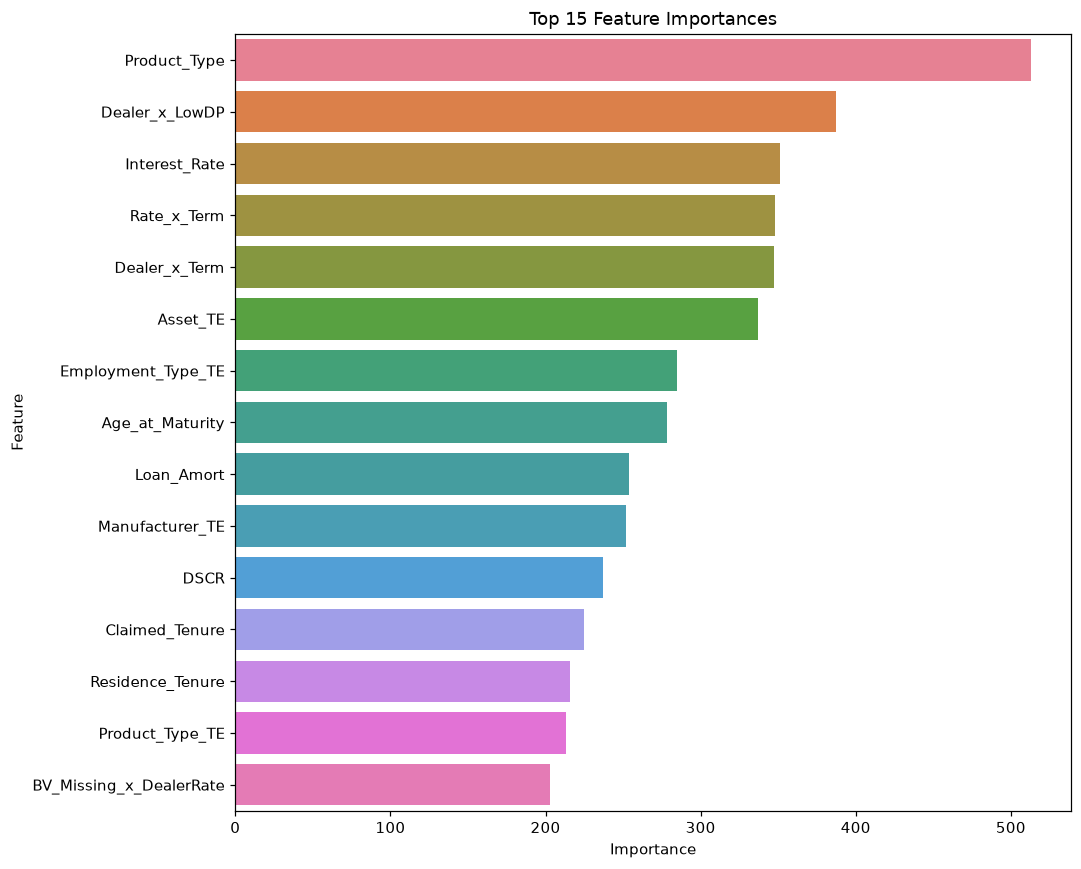

In [13]:
if hasattr(final_model, 'calibrated_classifiers_'):
    importances = np.mean(
        [c.estimator.feature_importances_ for c in final_model.calibrated_classifiers_],
        axis=0,
    )
else:
    importances = final_model.feature_importances_

importance_df = (
    pd.DataFrame({
        'Feature': X_train_val_cd.columns,
        'Importance': importances,
    })
    .sort_values('Importance', ascending=False)
)
importance_df = importance_df[importance_df['Importance'] > 0]
print("Top 20 feature importances:")
print(importance_df.head(20).to_string(index=False))

plt.figure(figsize=(10, 8))
sns.barplot(data=importance_df.head(15), x='Importance', y='Feature', hue='Feature', legend=False)
plt.title("Top 15 Feature Importances")
plt.tight_layout()
plt.show()

### Error Profiling

In [14]:
df_eval = X_test_cd.copy()
df_eval['y_true'] = y_test.values
df_eval['y_pred'] = y_pred

TP_df = df_eval[(df_eval['y_true'] == 1) & (df_eval['y_pred'] == 1)]
FN_df = df_eval[(df_eval['y_true'] == 1) & (df_eval['y_pred'] == 0)]
TN_df = df_eval[(df_eval['y_true'] == 0) & (df_eval['y_pred'] == 0)]
FP_df = df_eval[(df_eval['y_true'] == 0) & (df_eval['y_pred'] == 1)]
print(f"TP: {len(TP_df)} | FN: {len(FN_df)} | TN: {len(TN_df)} | FP: {len(FP_df)}")


def run_mannwhitney(g1, g2, n1, n2):
    results = []
    for col in X_test_cd.columns:
        if not pd.api.types.is_numeric_dtype(df_eval[col]):
            continue
        a, b = g1[col].dropna(), g2[col].dropna()
        if len(a) < 5 or len(b) < 5:
            continue
        _, pval = mannwhitneyu(a, b, alternative='two-sided')
        if pval < 0.05:
            results.append({
                'Feature': col,
                f'{n1}_Median': round(a.median(), 4),
                f'{n2}_Median': round(b.median(), 4),
                'P_Value': round(pval, 5),
            })
    return pd.DataFrame(results).sort_values('P_Value').reset_index(drop=True) if results else pd.DataFrame()


print("\n[1] TP vs FN — what separates caught defaults from missed ones:")
tp_fn = run_mannwhitney(TP_df, FN_df, 'TP', 'FN')
if not tp_fn.empty:
    print(tp_fn.head(10).to_string(index=False))

print("\n[2] TN vs FP — what separates correct approvals from false alarms:")
tn_fp = run_mannwhitney(TN_df, FP_df, 'TN', 'FP')
if not tn_fp.empty:
    print(tn_fp.head(10).to_string(index=False))

TP: 88 | FN: 620 | TN: 1999 | FP: 138

[1] TP vs FN — what separates caught defaults from missed ones:
                       Feature  TP_Median  FN_Median  P_Value
                 Dealer_x_Term    13.6338    10.3662      0.0
        BAP_Adverse_Loans_Only     0.0000     0.0000      0.0
                Dealer_x_LowDP     0.1839     0.1531      0.0
                 Payment_Terms    60.0000    48.0000      0.0
              Dealer_Risk_Tier     1.0000     0.0000      0.0
           Dealer_Default_Rate     0.2601     0.2073      0.0
                Dealer_Name_TE     0.2451     0.2073      0.0
                   Rate_x_Term  1463.9683  1166.6299      0.0
Verification_Gaps_x_DealerRate     1.0000     0.8293      0.0
              High_Risk_Dealer     0.0000     0.0000      0.0

[2] TN vs FP — what separates correct approvals from false alarms:
               Feature  TN_Median  FP_Median  P_Value
        MOP_Risk_Score     2.0000     2.0000      0.0
BAP_Adverse_Loans_Only     0.0000     0

### SHAP Analysis

-- Global SHAP Summary --


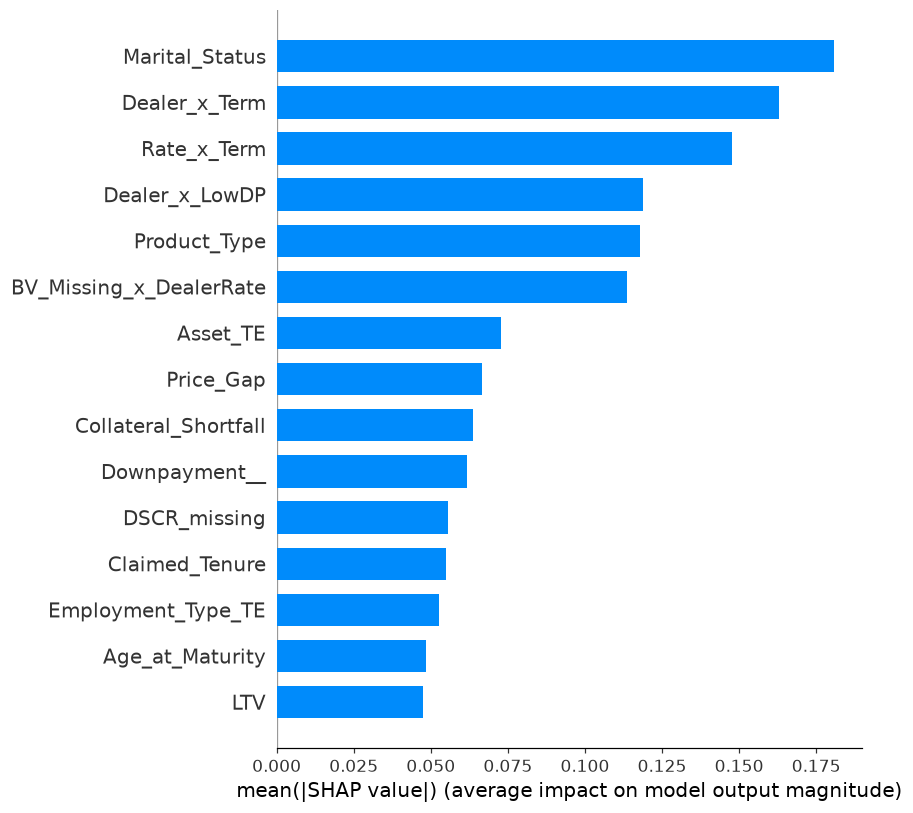

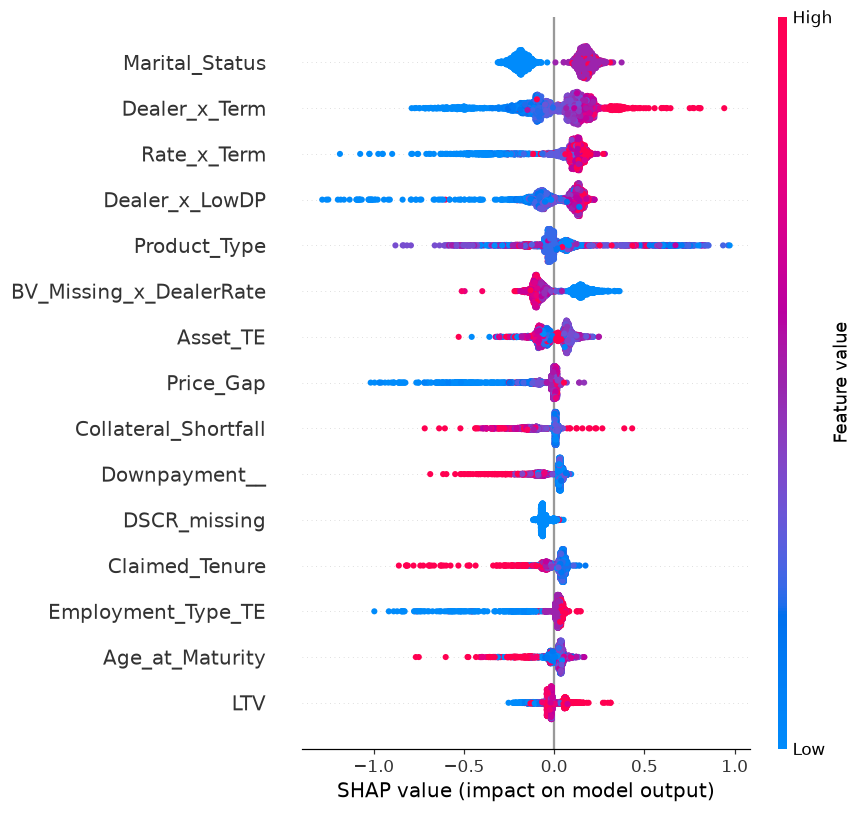

In [15]:
lgbm_base = final_model.calibrated_classifiers_[0].estimator if hasattr(final_model, 'calibrated_classifiers_') else final_model
explainer = shap.TreeExplainer(lgbm_base)
shap_values = explainer.shap_values(X_test_cd)
if isinstance(shap_values, list):
    sv = shap_values[1]
elif getattr(shap_values, 'ndim', 2) == 3:
    sv = shap_values[:, :, 1]
else:
    sv = shap_values

print("-- Global SHAP Summary --")
shap.summary_plot(sv, X_test_cd, plot_type='bar', max_display=15, show=True)
shap.summary_plot(sv, X_test_cd, max_display=15, show=True)

-- Top features driving MISSED defaults (FN) --
                Feature  FN_mean_SHAP  TP_mean_SHAP
         Marital_Status      0.178537      0.188122
          Dealer_x_Term      0.158463      0.217677
            Rate_x_Term      0.137924      0.129897
BV_Missing_x_DealerRate      0.116086      0.139583
         Dealer_x_LowDP      0.109640      0.117981
           Product_Type      0.107857      0.165290
               Asset_TE      0.067965      0.055452
              Price_Gap      0.063123      0.019839
   Collateral_Shortfall      0.056926      0.022211
           DSCR_missing      0.054682      0.044656
          Downpayment__      0.051365      0.033762
         Claimed_Tenure      0.051228      0.036221
        Age_at_Maturity      0.048697      0.043547
     Employment_Type_TE      0.048386      0.036509
         Home_Ownership      0.045681      0.038849

-- Features pushing FN cases toward LOW RISK (negative SHAP) --
                       Feature  Avg_negative_push
     

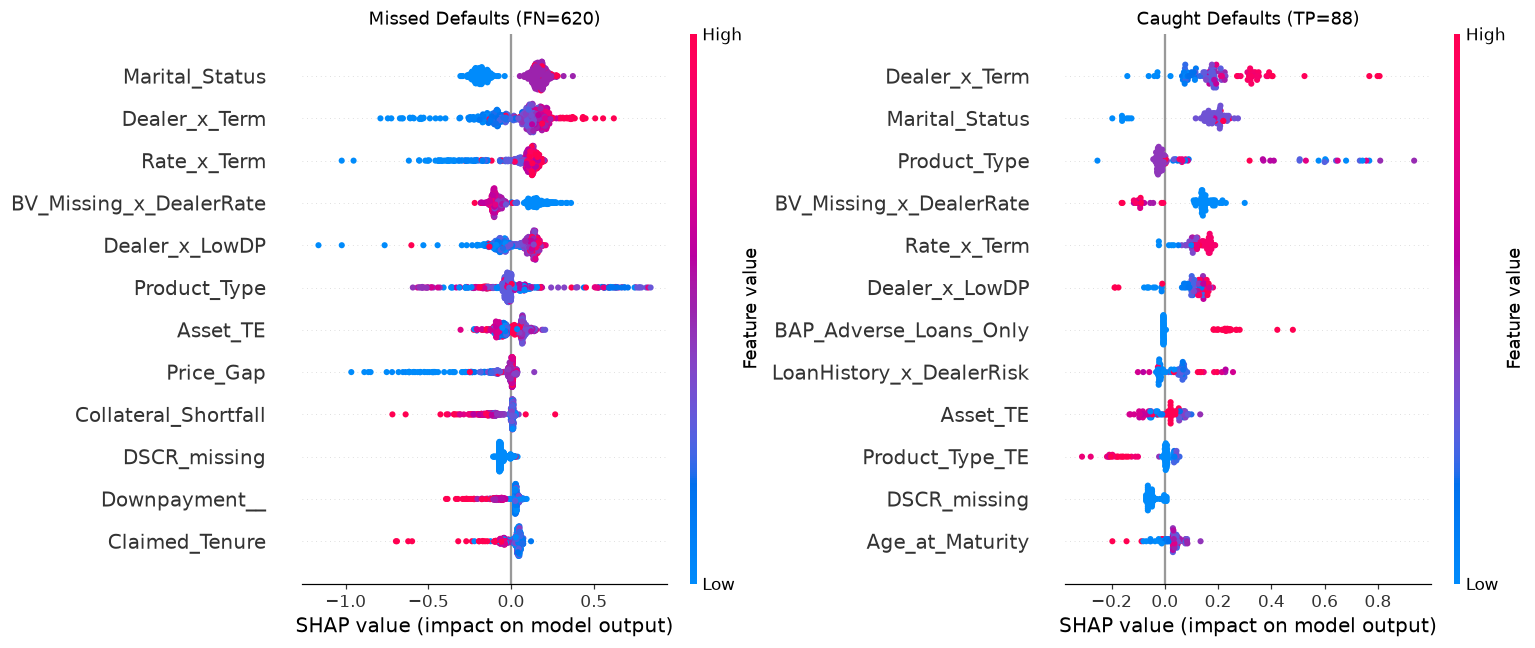

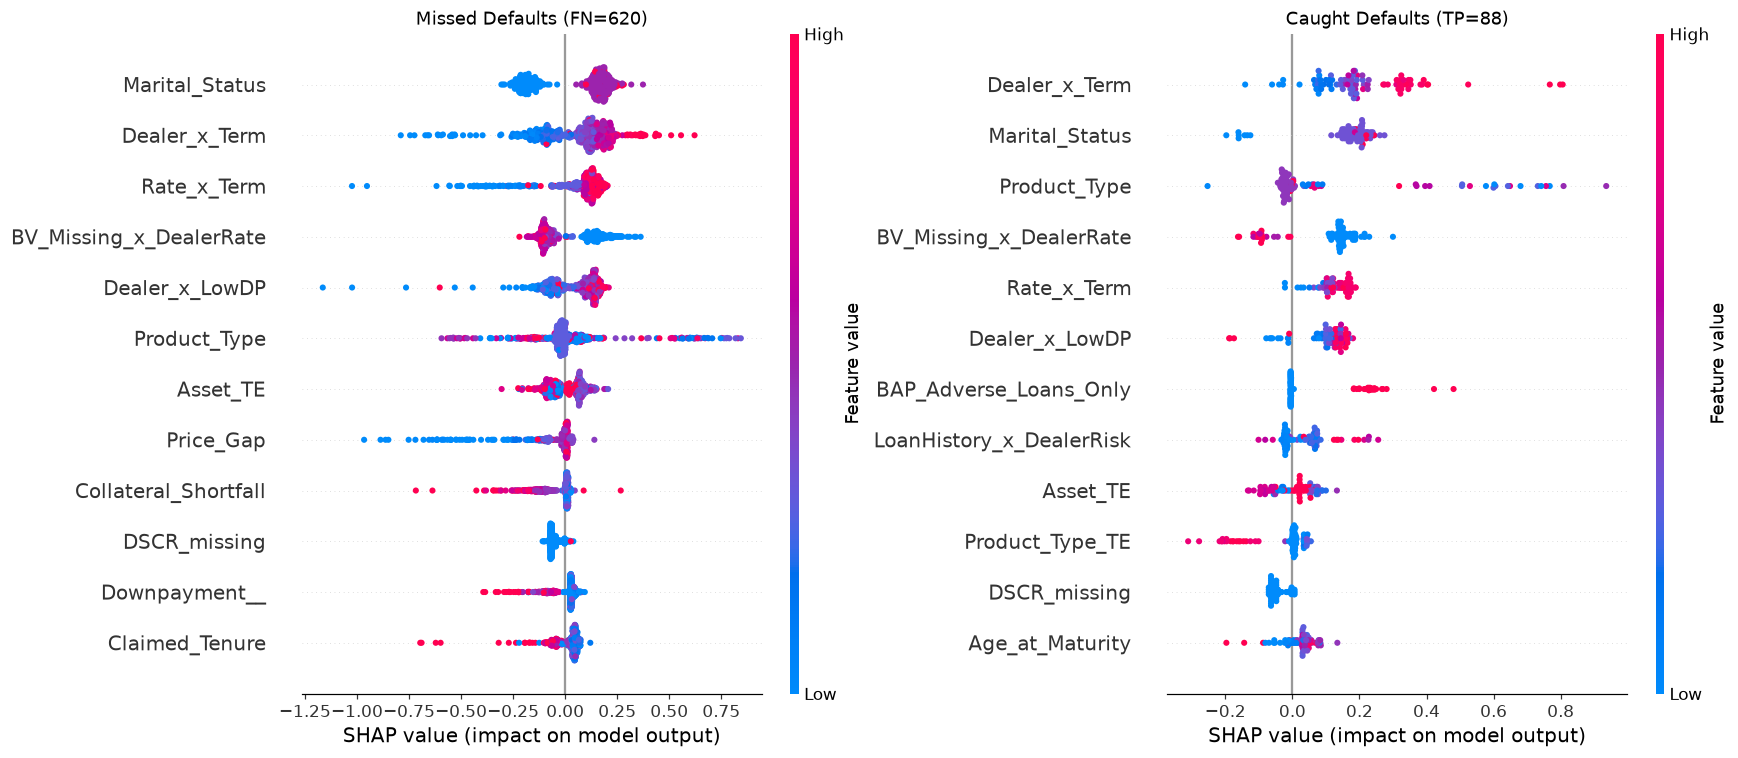

In [16]:
fn_mask = (y_test.values == 1) & (y_pred == 0)
tp_mask = (y_test.values == 1) & (y_pred == 1)

if fn_mask.sum() > 0 and tp_mask.sum() > 0:
    sv_fn = sv[fn_mask]
    sv_tp = sv[tp_mask]

    fn_mean_shap = pd.DataFrame({
        'Feature': X_test_cd.columns,
        'FN_mean_SHAP': np.abs(sv_fn).mean(axis=0),
        'TP_mean_SHAP': np.abs(sv_tp).mean(axis=0),
    }).sort_values('FN_mean_SHAP', ascending=False)

    print("-- Top features driving MISSED defaults (FN) --")
    print(fn_mean_shap.head(15).to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    plt.sca(axes[0])
    shap.summary_plot(sv_fn, X_test_cd[fn_mask], max_display=12, show=False, plot_size=None)
    axes[0].set_title(f'Missed Defaults (FN={fn_mask.sum()})')
    plt.sca(axes[1])
    shap.summary_plot(sv_tp, X_test_cd[tp_mask], max_display=12, show=False, plot_size=None)
    axes[1].set_title(f'Caught Defaults (TP={tp_mask.sum()})')
    plt.tight_layout()
    plt.show()

    print("\n-- Features pushing FN cases toward LOW RISK (negative SHAP) --")
    fn_neg = pd.DataFrame({
        'Feature': X_test_cd.columns,
        'Avg_negative_push': sv_fn.mean(axis=0),
    }).sort_values('Avg_negative_push').head(10)
    print(fn_neg.to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    plt.sca(axes[0])
    shap.summary_plot(sv_fn, X_test_cd[fn_mask], max_display=12, show=False, plot_type='dot', plot_size=None)
    axes[0].set_title(f'Missed Defaults (FN={fn_mask.sum()})')
    plt.sca(axes[1])
    shap.summary_plot(sv_tp, X_test_cd[tp_mask], max_display=12, show=False, plot_type='dot', plot_size=None)
    axes[1].set_title(f'Caught Defaults (TP={tp_mask.sum()})')
    plt.tight_layout()
    plt.show()
else:
    print(f"Skipping FN vs TP SHAP comparison (FN={fn_mask.sum()}, TP={tp_mask.sum()}).")

### Export Original Train & Test Predictions CSV

In [17]:
from pathlib import Path


def _build_te_maps_from_train_part():
    X_tr_tmp, _ = split_xy_and_sanitize(train_part)
    y_tr_tmp = y_train.reset_index(drop=True)
    X_tr_tmp = X_tr_tmp.reset_index(drop=True)
    te_maps = {}
    for col in te_cols:
        s_tr = X_tr_tmp[col].fillna('Unknown').astype(str)
        grp = y_tr_tmp.groupby(s_tr).agg(['mean', 'count'])
        te_maps[col] = (
            grp['mean'] * grp['count'] + global_mean * TE_SMOOTH
        ) / (grp['count'] + TE_SMOOTH)
    return te_maps


_te_enc_maps = _build_te_maps_from_train_part()


def score_original_dataset(raw_df, dataset_label: str) -> pd.DataFrame:
    """Score every row of the original dataset while keeping all original rows and columns."""
    orig = pd.DataFrame(raw_df).copy().reset_index(drop=True)
    work = orig.copy()

    # Harmonize schema without dropping any rows (no drop_duplicates)
    if 'Unit Brand' in work.columns and 'Manufacturer' not in work.columns:
        work = work.rename(columns={'Unit Brand': 'Manufacturer'})
    work = work.drop(columns=['Product Type.1'], errors='ignore')
    if 'Borrower Type' not in work.columns:
        work['Borrower Type'] = 'Principal'
    work = work.drop(columns=COLS_TO_DROP_RAW, errors='ignore')
    if 'Current DPD' in work.columns and 'Longest_DPD' not in work.columns:
        work = work.rename(columns={'Current DPD': 'Longest_DPD'})

    # Ensure every column seen in raw train schema exists before feature engineering
    raw_ref_cols = [
        c for c in train_df.columns
        if c not in {'Target'} and not str(c).endswith('_missing')
    ]
    for col in raw_ref_cols:
        if col not in work.columns:
            work[col] = np.nan

    # Row-wise cleaning matching preprocess_individual_df (without Marital Status row filtering)
    income_cols = [c for c in ['Claimed Income', 'EV Income', 'BV Income'] if c in work.columns]
    tenure_cols = [c for c in ['Claimed Tenure', 'EV Tenure', 'BV Tenure', 'Residence Tenure'] if c in work.columns]

    for col in income_cols:
        num_s = pd.to_numeric(work[col], errors='coerce')
        mask = num_s.isnull()
        parsed = pd.to_numeric(work.loc[mask, col].apply(clean_income), errors='coerce')
        work[col] = num_s.where(~mask, parsed)

    for col in tenure_cols:
        num_s = pd.to_numeric(work[col], errors='coerce')
        mask = num_s.isnull()
        parsed = pd.to_numeric(work.loc[mask, col].apply(clean_tenure), errors='coerce')
        work[col] = num_s.where(~mask, parsed)

    if income_cols or tenure_cols:
        work[income_cols + tenure_cols] = work[income_cols + tenure_cols].apply(pd.to_numeric, errors='coerce')

    work['Longest_DPD'] = pd.to_numeric(work['Longest_DPD'], errors='coerce').fillna(0)

    flag_cols = [
        'BAP Amount', 'EV Income', 'EV Tenure',
        'BV Income', 'Price Gap', 'BV Tenure', 'DSCR',
        'Claimed Tenure', 'Claimed Income', 'Residence Tenure',
    ]
    for col in flag_cols:
        if col in work.columns:
            val_num = pd.to_numeric(work[col], errors='coerce')
            work[f'{col}_missing'] = (val_num.isnull() | (val_num == -999)).astype(int)
            work[col] = val_num.replace(-999, np.nan)

    num_cols = work.select_dtypes(include=[np.number]).columns
    work[num_cols] = work[num_cols].replace(-999, np.nan)

    cat_fill_cols = [
        'Loan History', 'BAP Type', 'Citizenship',
        'Type of Unit', 'Dealer Name', 'Borrower Type', 'Employment Type',
        'Home Ownership', 'Manufacturer', 'Submitted ID', 'Mode of Payment',
    ]
    for col in cat_fill_cols:
        if col in work.columns:
            work[col] = work[col].fillna('Unknown')

    if 'Contract Start Date' in work.columns:
        work['Contract Start Date'] = pd.to_datetime(
            work['Contract Start Date'], dayfirst=True, errors='coerce'
        ).fillna(contract_date_mode)
        work['Contract_Year'] = work['Contract Start Date'].dt.year
        work['Contract_Month'] = work['Contract Start Date'].dt.month
        work = work.drop(columns=['Contract Start Date'])

    work = work.drop(columns=['Birthday', 'BAP Date'], errors='ignore')

    if 'Marital Status' in work.columns:
        work['Marital Status'] = work['Marital Status'].replace({
            'Separated': 'Without Partner',
            'Divorced': 'Without Partner',
            'Single': 'Single/Not Married',
            'Not Married': 'Single/Not Married',
        })

    work['Target'] = work['Longest_DPD'].apply(lambda x: 0 if pd.isna(x) or x <= 0 else 1)

    for col, (lo, hi) in winsor_bounds.items():
        if col in work.columns and pd.notna(lo) and pd.notna(hi):
            work[col] = work[col].clip(lower=lo, upper=hi)

    work = engineer_row_features(work)
    work['High_DTI'] = (work['DTI'] > dti_q75_train).astype(int)

    X_s, _ = split_xy_and_sanitize(work)
    X_s.drop(columns=[c for c in drop_cols if c in X_s.columns], inplace=True)

    # Apply train-only CategoricalDtype before encodings
    for col, dtype in train_cat_dtypes.items():
        if col not in X_s.columns:
            X_s[col] = 'Unknown'
        X_s[col] = X_s[col].fillna('Unknown').astype(str).astype(dtype)

    if dealer_col_name in X_s.columns:
        rates = X_s[dealer_col_name].astype(str).map(dealer_smooth).fillna(global_rate)
        _assign_dealer_features(X_s, rates, _full_train_tier(rates))

    for col in te_cols:
        X_s[f'{col}_TE'] = X_s[col].astype(str).map(_te_enc_maps[col]).fillna(global_mean).values

    X_s.drop(columns=[c for c in drop_high_card if c in X_s.columns], inplace=True)

    for col in active_cats:
        X_s[col] = X_s[col].cat.codes

    if impute_cols_present:
        X_s[impute_cols_present] = imputer.transform(X_s[impute_cols_present])

    for col in X_s.select_dtypes(include=[np.number]).columns:
        if X_s[col].isnull().any():
            X_s[col] = X_s[col].fillna(train_medians.get(col, 0.0))

    for feat in strong_split:
        if feat in X_s.columns and cohens_d_best.get(feat) is not None:
            X_s[f'{feat}_cd_split'] = (X_s[feat] <= cohens_d_best[feat]).astype(int)

    X_s = X_s.reindex(columns=X_train_val_cd.columns, fill_value=0)

    proba = final_model.predict_proba(X_s)
    orig['Predicted_Class'] = (proba[:, 1] >= best_thresh).astype(int)
    orig['Prob_Class_0'] = proba[:, 0]
    print(f"[{dataset_label}] Scored {len(orig)} original rows x {orig.shape[1]} columns.")
    return orig


train_scored_df = score_original_dataset(train, 'train')
test_scored_df = score_original_dataset(test, 'test')

# Sanity check: all 2,845 test rows match final_model evaluation predictions bit-for-bit
assert np.array_equal(test_scored_df['Predicted_Class'].to_numpy(), y_pred), "Test Predicted_Class mismatch!"
assert np.allclose(test_scored_df['Prob_Class_0'].to_numpy(), 1.0 - test_proba), "Test Prob_Class_0 mismatch!"

out_dir = Path('ModelUpdatation_Referance') if Path('ModelUpdatation_Referance').is_dir() else Path('.')

# Combined single CSV with all original rows & columns from both train and test files
combined_scored_df = pd.concat(
    [
        train_scored_df.assign(Dataset='train'),
        test_scored_df.assign(Dataset='test'),
    ],
    ignore_index=True,
    sort=False,
)
combined_csv = out_dir / 'train_test_predictions_DPD_gt0.csv'
combined_scored_df.to_csv(combined_csv, index=False)

# Also save per-dataset CSVs preserving each file's exact original column schema
train_csv = out_dir / 'train_predictions_DPD_gt0.csv'
test_csv = out_dir / 'test_predictions_DPD_gt0.csv'
train_scored_df.to_csv(train_csv, index=False)
test_scored_df.to_csv(test_csv, index=False)

print(f"Saved combined CSV : {combined_csv} {combined_scored_df.shape}")
print(f"Saved train CSV    : {train_csv} {train_scored_df.shape}")
print(f"Saved test CSV     : {test_csv} {test_scored_df.shape}")

[train] Scored 22300 original rows x 40 columns.
[test] Scored 2845 original rows x 50 columns.
Saved combined CSV : ModelUpdatation_Referance\train_test_predictions_DPD_gt0.csv (25145, 53)
Saved train CSV    : ModelUpdatation_Referance\train_predictions_DPD_gt0.csv (22300, 40)
Saved test CSV     : ModelUpdatation_Referance\test_predictions_DPD_gt0.csv (2845, 50)
